## VALIDACIÓN DE PCA Y DBSCAN SOBRE EL DATASET ELECTORAL
Comprueba la varianza acumulada de PCA sobre las 28 características procesadas, sin ponderar y después de aplicar los pesos. Compara DBSCAN con y sin PCA manteniendo los parámetros de las ejecuciones originales. Los resultados se guardan en `results/aditional_validation/pca_dbscan/`.

### INICIALIZACIÓN

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score, adjusted_mutual_info_score, silhouette_score,
    davies_bouldin_score, calinski_harabasz_score
)

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src').is_dir() and (path / 'data').is_dir()
)
sys.path.insert(0, str(project_root))
dataset_path = project_root / 'data/processed/lapop_bolivia_2023_processed.csv'
weights_path = project_root / 'src/weighting/schemas/feature_weights.json'
output_dir = project_root / 'results/aditional_validation/pca_dbscan'
output_dir.mkdir(parents=True, exist_ok=True)

X = pd.read_csv(dataset_path)
with weights_path.open(encoding='utf-8') as file:
    weight_config = json.load(file)['features']
weights = pd.Series({column: float(weight_config[column]) for column in X.columns})

assert X.shape == (1706, 28), 'Se esperaba el dataset electoral de 1706 registros y 28 características.'
assert X.notna().all().all(), 'El dataset procesado contiene valores faltantes.'
np.random.seed(42)
sns.set_style('whitegrid')

print('=' * 70)
print('VALIDACIÓN DE PCA Y DBSCAN SOBRE DATASET ELECTORAL')
print('=' * 70)
print(f'Dataset: {X.shape[0]} registros x {X.shape[1]} características')
print(f'Pesos: [{weights.min():.2f}, {weights.max():.2f}]')
print(f'Resultados: {output_dir.relative_to(project_root)}')

VALIDACIÓN DE PCA Y DBSCAN SOBRE DATASET ELECTORAL
Dataset: 1706 registros x 28 características
Pesos: [0.50, 1.00]
Resultados: results\aditional_validation\pca_dbscan


### VARIANZA ACUMULADA Y NÚMERO DE COMPONENTES
Se ajusta PCA a las características sin ponderar y al espacio `X * weights`. Se obtiene la varianza acumulada para cada componente y el número mínimo que alcanza los umbrales de 80%, 85%, 90% y 95%.

In [2]:
Xw = X.mul(weights, axis=1)
pca_u_full = PCA().fit(X)
pca_w_full = PCA().fit(Xw)
cum_u = np.cumsum(pca_u_full.explained_variance_ratio_)
cum_w = np.cumsum(pca_w_full.explained_variance_ratio_)

def min_components(cum, target):
    return int(np.searchsorted(cum, target) + 1)

variance_table = pd.DataFrame({
    'component':np.arange(1, X.shape[1]+1),
    'evr_unweighted':pca_u_full.explained_variance_ratio_,
    'cumulative_unweighted':cum_u,
    'evr_weighted_X_times_w':pca_w_full.explained_variance_ratio_,
    'cumulative_weighted_X_times_w':cum_w
})
variance_table.to_csv(output_dir / 'pca_explained_variance_by_component.csv', index=False)

threshold_rows=[]
for target in [.80,.85,.90,.95]:
    ku=min_components(cum_u,target)
    kw=min_components(cum_w,target)
    threshold_rows += [
        {'space':'unweighted_processed','target':target,'n_components':ku,'cumulative_variance':cum_u[ku-1]},
        {'space':'weighted_X_times_w','target':target,'n_components':kw,'cumulative_variance':cum_w[kw-1]}
    ]
thresholds=pd.DataFrame(threshold_rows)
thresholds.to_csv(output_dir / 'pca_components_by_threshold.csv', index=False)
display(thresholds.round(4))

,space,target,n_components,cumulative_variance
0,unweighted_processed,0.80,13,0.8090
1,weighted_X_times_w,0.80,12,0.8082
2,unweighted_processed,0.85,15,0.8561
3,weighted_X_times_w,0.85,14,0.8510
4,unweighted_processed,0.90,18,0.9084
5,weighted_X_times_w,0.90,17,0.9051
6,unweighted_processed,0.95,22,0.9579
7,weighted_X_times_w,0.95,21,0.9590


In [3]:
display(variance_table.loc[variance_table['component'].isin([16, 17, 18]), ['component', 'cumulative_unweighted', 'cumulative_weighted_X_times_w']].round(6))

,component,cumulative_unweighted,cumulative_weighted_X_times_w
15,16,0.876405,0.888489
16,17,0.892944,0.905078
17,18,0.908403,0.920628


### PCA PARA DBSCAN Y PARA VISUALIZACIÓN
Se distinguen las 18 componentes sin ponderar de DBSCAN, las 17 componentes del espacio ponderado de W-DBSCAN y la proyección independiente de dos componentes utilizada para visualización. La varianza se refiere al espacio de entrada de cada PCA.

In [4]:
pca2 = PCA(n_components=2, random_state=42).fit(X)
pca_audit = pd.DataFrame([
    {'use':'traditional_dbscan','input':'28_unweighted_features','n_components':18,'cumulative_variance':cum_u[17]},
    {'use':'weighted_dbscan','input':'weighted_X_times_w','n_components':17,'cumulative_variance':cum_w[16]},
    {'use':'2d_visualization','input':'28_unweighted_features','n_components':2,'cumulative_variance':pca2.explained_variance_ratio_.sum()}
])
pca_audit.to_csv(output_dir / 'pca_representation_audit.csv', index=False)
display(pca_audit.round(4))

,use,input,n_components,cumulative_variance
0,traditional_dbscan,28_unweighted_features,18,0.9084
1,weighted_dbscan,weighted_X_times_w,17,0.9051
2,2d_visualization,28_unweighted_features,2,0.2832


### CARGAS DE LAS DOS PRIMERAS COMPONENTES

In [5]:
load_rows=[]
for space, pca in [('unweighted',pca_u_full),('weighted_X_times_w',pca_w_full)]:
    for pc in [0,1]:
        order=np.argsort(np.abs(pca.components_[pc]))[::-1][:8]
        for rank,j in enumerate(order,1):
            load_rows.append({'space':space,'component':pc+1,'rank':rank,'feature':X.columns[j],
                              'loading':pca.components_[pc,j],'abs_loading':abs(pca.components_[pc,j])})
loadings=pd.DataFrame(load_rows)
loadings.to_csv(output_dir / 'pca_top_loadings_pc1_pc2.csv', index=False)
display(loadings)

,space,component,rank,feature,loading,abs_loading
0,unweighted,1,1,estratosec,0.576700,0.576700
1,unweighted,1,2,ur,-0.566482,0.566482
2,unweighted,1,3,boletidnew,0.388807,0.388807
3,unweighted,1,4,bolcct1b,0.270950,0.270950
4,unweighted,1,5,wealth_index,-0.173369,0.173369
5,unweighted,1,6,edre,-0.164395,0.164395
6,unweighted,1,7,boletidnewb,0.117399,0.117399
7,unweighted,1,8,bolcct1c,0.111655,0.111655
8,unweighted,2,1,bolcct1a,0.736977,0.736977
9,unweighted,2,2,bolcct1b,-0.579293,0.579293


In [6]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(range(1,29),cum_u,marker='o',ms=3,label='Sin ponderar')
ax.plot(range(1,29),cum_w,marker='o',ms=3,label='X × pesos históricos')
ax.axhline(.90,color='black',ls='--',lw=1)
ax.axvline(18,color='#4777a8',ls=':',lw=1)
ax.axvline(17,color='#b44b4b',ls=':',lw=1)
ax.set(xlabel='Número de componentes',ylabel='Varianza acumulada',title='Construcción empírica de PCA 18 y PCA 17',ylim=(0,1.02))
ax.legend()
fig.tight_layout()
fig.savefig(output_dir/'pca_cumulative_variance.png',dpi=180,bbox_inches='tight')
plt.show()

<Figure size 800x500 with 1 Axes>

### DBSCAN CON Y SIN PCA
Se conservan `eps=0.98` y `min_samples=36` para DBSCAN tradicional, y `eps=0.606` y `min_samples=34` para la representación ponderada. La prueba examina sensibilidad a la representación, sin reoptimizar parámetros. Las métricas internas se calculan solo cuando hay al menos dos clusters y excluyen las observaciones clasificadas como ruido.

In [7]:
def safe_dbscan_summary(name, data, eps, min_samples):
    labels = DBSCAN(eps=eps, min_samples=min_samples, metric='euclidean', n_jobs=-1).fit_predict(data)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    row = {'configuration':name,'eps':eps,'min_samples':min_samples,'n_features':data.shape[1],
           'n_total':len(labels),'n_assigned':int(mask.sum()),'coverage_pct':100*mask.mean(),
           'n_noise':int((~mask).sum()),'noise_pct':100*(~mask).mean(),'n_clusters':n_clusters,
           'silhouette':np.nan,'davies_bouldin':np.nan,'calinski_harabasz':np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        row['silhouette']=silhouette_score(data[mask], labels[mask])
        row['davies_bouldin']=davies_bouldin_score(data[mask], labels[mask])
        row['calinski_harabasz']=calinski_harabasz_score(data[mask], labels[mask])
    return row, labels

Xu18 = PCA(n_components=18, random_state=42).fit_transform(X)
Xw17 = PCA(n_components=17, random_state=42).fit_transform(Xw)

configs = [
    ('Traditional: 28 features without PCA', X.to_numpy(), .98, 36, 'trad_full'),
    ('Traditional: PCA 18', Xu18, .98, 36, 'trad_pca'),
    ('Weighted: 28 X*weights without PCA', Xw.to_numpy(), .606, 34, 'weig_full'),
    ('Weighted: PCA 17', Xw17, .606, 34, 'weig_pca')
]
rows, db_labels = [], {}
for name,data,eps,ms,key in configs:
    row, labels = safe_dbscan_summary(name,data,eps,ms)
    rows.append(row)
    db_labels[key]=labels
dbscan_compare=pd.DataFrame(rows)
dbscan_compare.to_csv(output_dir/'dbscan_with_without_pca.csv',index=False)
display(dbscan_compare.round(4))

,configuration,eps,min_samples,n_features,n_total,n_assigned,coverage_pct,n_noise,noise_pct,n_clusters,silhouette,davies_bouldin,calinski_harabasz
0,Traditional: 28 features without PCA,0.980,36,28,1706,36,2.1102,1670,97.8898,1,NaN,NaN,NaN
1,Traditional: PCA 18,0.980,36,18,1706,494,28.9566,1212,71.0434,6,0.2614,1.5008,128.8969
2,Weighted: 28 X*weights without PCA,0.606,34,28,1706,0,0.0000,1706,100.0000,0,NaN,NaN,NaN
3,Weighted: PCA 17,0.606,34,17,1706,296,17.3505,1410,82.6495,4,0.2958,1.3593,120.3061


### COMPARACIÓN DE ASIGNACIONES Y COBERTURA
ARI y AMI incluyen el ruido. Jaccard compara los conjuntos de observaciones agrupadas con y sin PCA. Si cambia la cobertura o el espacio evaluado, las métricas internas no representan una comparación directa de superioridad.

In [8]:
pair_rows=[]
for family,a,b in [('traditional','trad_full','trad_pca'),('weighted','weig_full','weig_pca')]:
    la,lb=db_labels[a],db_labels[b]
    ca,cb=la!=-1,lb!=-1
    intersection=np.sum(ca & cb)
    union=np.sum(ca | cb)
    pair_rows.append({'family':family,'ari_including_noise':adjusted_rand_score(la,lb),
                      'ami_including_noise':adjusted_mutual_info_score(la,lb),
                      'assigned_membership_jaccard':intersection/union if union else np.nan,
                      'assigned_in_both':intersection,'assigned_union':union})
dbscan_membership=pd.DataFrame(pair_rows)
dbscan_membership.to_csv(output_dir/'dbscan_membership_with_without_pca.csv',index=False)
display(dbscan_membership.round(4))

,family,ari_including_noise,ami_including_noise,assigned_membership_jaccard,assigned_in_both,assigned_union
0,traditional,0.0825,0.1027,0.0729,36,494
1,weighted,0.0000,0.0000,0.0000,0,296


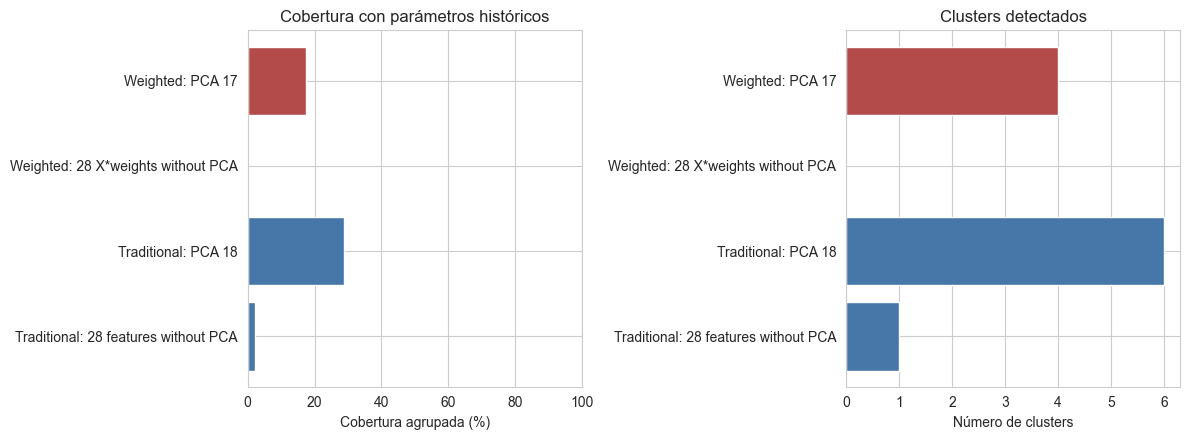

In [9]:
fig, axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].barh(dbscan_compare.configuration,dbscan_compare.coverage_pct,color=['#4777a8','#4777a8','#b44b4b','#b44b4b'])
axes[0].set(xlabel='Cobertura agrupada (%)',title='Cobertura con parámetros históricos',xlim=(0,100))
axes[1].barh(dbscan_compare.configuration,dbscan_compare.n_clusters,color=['#4777a8','#4777a8','#b44b4b','#b44b4b'])
axes[1].set(xlabel='Número de clusters',title='Clusters detectados')
fig.tight_layout()
fig.savefig(output_dir/'dbscan_coverage_with_without_pca.png',dpi=180,bbox_inches='tight')
plt.show()